In [1]:
# Load the training labels

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

TRAIN_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "splits"
    / "train.csv"
)

y_train = pd.read_csv(
    TRAIN_PATH,
    usecols=["isFraud"]
)["isFraud"]

print("Training labels loaded")
print("Total training records:", len(y_train))
print("\nClass distribution:")
print(y_train.value_counts().sort_index())


Training labels loaded
Total training records: 4453833

Class distribution:
isFraud
0    4448084
1       5749
Name: count, dtype: int64


In [2]:
# Calculate the imbalance ratio


class_counts = y_train.value_counts().sort_index()

legitimate_count = int(class_counts.get(0, 0))
fraud_count = int(class_counts.get(1, 0))

fraud_percentage = (
    fraud_count / len(y_train)
) * 100

imbalance_ratio = (
    legitimate_count / fraud_count
)

print(f"Legitimate transactions: {legitimate_count:,}")
print(f"Fraudulent transactions: {fraud_count:,}")
print(f"Fraud percentage: {fraud_percentage:.4f}%")
print(f"Legitimate-to-fraud ratio: {imbalance_ratio:.2f}:1")


Legitimate transactions: 4,448,084
Fraudulent transactions: 5,749
Fraud percentage: 0.1291%
Legitimate-to-fraud ratio: 773.71:1


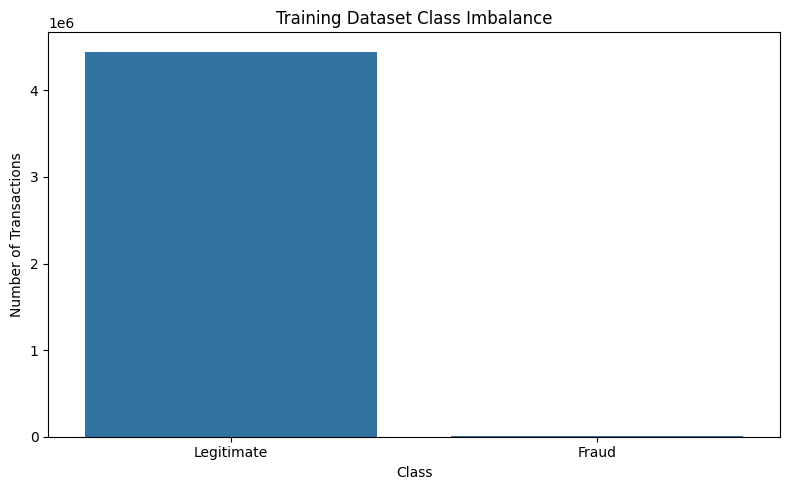

In [3]:
# Visualize the class distribution


class_summary = pd.DataFrame({
    "Class": ["Legitimate", "Fraud"],
    "Count": [legitimate_count, fraud_count]
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=class_summary,
    x="Class",
    y="Count"
)

plt.title("Training Dataset Class Imbalance")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()


In [4]:
# calculate class weigjts


from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train.to_numpy()
)

class_weights = dict(zip(classes, weights))

print("Balanced class weights:")
print(class_weights)

scale_pos_weight = (
    legitimate_count / fraud_count
)

print(
    "\nXGBoost scale_pos_weight:",
    round(scale_pos_weight, 2)
)


Balanced class weights:
{np.int64(0): np.float64(0.500646233299551), np.int64(1): np.float64(387.357192555227)}

XGBoost scale_pos_weight: 773.71
